In [1]:
!pip install nltk textblob wordcloud vaderSentiment seaborn scikit-learn langdetect

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import nltk
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

nltk.download("vader_lexicon")

warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)



[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\home\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [2]:
df = pd.read_csv('youtube_comments.csv', encoding='utf-8')


In [3]:
df.head(5)

,video_id,video_title,comment
0,TcMBFSGVi1c,Avengers Endgame Trailer,Furei a boca com espinho de peixe
1,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
2,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...
3,TcMBFSGVi1c,Avengers Endgame Trailer,TOMORROW. DOOM COMES FOR US ALL.
4,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today


In [4]:
import pandas as pd
from langdetect import detect, DetectorFactory

# Make language detection deterministic across runs
DetectorFactory.seed = 42

# 1. Drop empty comments first
df = df.dropna(subset=['comment', 'video_title']).copy()

# 2. Filter for Avengers videos (case-insensitive)
avengers_df = df[df['video_title'].str.contains('avengers', case=False, na=False)].copy()

# 3. Helper function to safely detect English text
def is_english(text):
    try:
        return detect(str(text)) == 'en'
    except:
        return False

# 4. Keep only English comments
avengers_en_df = avengers_df[avengers_df['comment'].apply(is_english)].copy()

print(f"Total rows: {len(df)}")
print(f"Avengers rows: {len(avengers_df)}")
print(f"Avengers + English rows: {len(avengers_en_df)}")

# Save filtered
avengers_en_df.to_csv('Avengers_Movie_trailer_review.csv', index=False, encoding='utf-8-sig')

Total rows: 66802
Avengers rows: 8409
Avengers + English rows: 5294


In [5]:
avengers_en_df.head(5)

,video_id,video_title,comment
1,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
2,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...
4,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today
5,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...
7,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...


# Open the newly saved file

In [6]:
Avengers_trailer = pd.read_csv('Avengers_Movie_trailer_review.csv')

# Exploratory Data Analysis

In [7]:
Avengers_trailer.head(5)

,video_id,video_title,comment
0,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
1,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...
2,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today
3,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...
4,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...


In [8]:
Avengers_trailer.shape

(5294, 3)

In [9]:
Avengers_trailer.describe()

,video_id,video_title,comment
count,5294,5294,5294
unique,11,1,5294
top,KCSNFZKbhZE,Avengers Endgame Trailer,Sou budista Jesus Cristo
freq,788,5294,1


In [10]:
Avengers_trailer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5294 entries, 0 to 5293
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_id     5294 non-null   object
 1   video_title  5294 non-null   object
 2   comment      5294 non-null   object
dtypes: object(3)
memory usage: 124.2+ KB


In [11]:
Avengers_trailer = Avengers_trailer.drop(0)

In [12]:
Avengers_trailer.head(5)


,video_id,video_title,comment
1,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...
2,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today
3,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...
4,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...
5,TcMBFSGVi1c,Avengers Endgame Trailer,Endgame coming back to cinemas for doomsday I ...


In [13]:
def clean_Avengers_trailer(comment):
    comment = re.sub(r"http\S+|www\.\S+", " ", comment)   # URLs
    comment = re.sub(r"@\w+", " ", comment)               # @mentions
    comment = comment.replace("&amp;", "&").replace("#", "")
    return re.sub(r"\s+", " ", comment).strip()

Avengers_trailer['clean'] = Avengers_trailer["comment"].apply(clean_Avengers_trailer)
Avengers_trailer[['comment', 'clean']].sample(5)

,comment,clean
3376,Who’s here after watching the Black Widow big ...,Who’s here after watching the Black Widow big ...
2914,No matter how short this trailer is but it is ...,No matter how short this trailer is but it is ...
2057,Infinity Saga vibe is like LoTR trilogy or Sta...,Infinity Saga vibe is like LoTR trilogy or Sta...
2051,VOLTA STARK TONY,VOLTA STARK TONY
364,Still giving goosebumps when they enter in tim...,Still giving goosebumps when they enter in tim...


In [14]:
Avengers_trailer.head(5)

,video_id,video_title,comment,clean
1,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...,Is there any chance of iron man returning back...
2,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today,saw this movie again today
3,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...,i’m discovering plot elements watching this tr...
4,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...,I was too young to have known about avengers w...
5,TcMBFSGVi1c,Avengers Endgame Trailer,Endgame coming back to cinemas for doomsday I ...,Endgame coming back to cinemas for doomsday I ...


In [15]:
import re
import nltk
from nltk.corpus import words

nltk.download("words")

english_vocab = set(w.lower() for w in words.words())
marvel_slang = {
    "avengers", "endgame", "thanos", "ironman", "spidey", "spiderman",
    "thor", "loki", "hulk", "hawkeye", "natasha", "wandavision", "mcu",
    "trailer", "teasers", "teaser", "doomsday", "ultron", "wakanda",
    "multiverse", "snap", "rewatch", "youtube", "omg", "lol", "bro",
    "bruh", "idk", "ngl", "imo", "tbh", "wtf", "gonna", "wanna", "gotta",
    "rdj", "cap", "stark", "rogers", "romanoff", "barton", "banner",
    "strange", "gamora", "nebula", "groot", "rocket", "drax", "mantis",
    "vision", "wanda", "brie", "larson", "holland", "evans", "hemsworth",
    "ruffalo", "johansson", "renner", "brolin", "russo", "feige", "stan"
}
valid_words = english_vocab.union(marvel_slang)

def is_clean_english(text, min_ratio=0.70):
    tokens = re.findall(r"[a-zA-Z]+", str(text).lower())
    if not tokens:
        return False
    known_count = sum(1 for t in tokens if t in valid_words)
    return (known_count / len(tokens)) >= min_ratio

# Check which rows get flagged WITHOUT modifying Avengers_trailer yet
keep_mask = Avengers_trailer["clean"].apply(is_clean_english)
dropped_preview = Avengers_trailer[~keep_mask]

[nltk_data] Downloading package words to
[nltk_data]     C:\Users\home\AppData\Roaming\nltk_data...
[nltk_data]   Package words is already up-to-date!


# Word Cloud

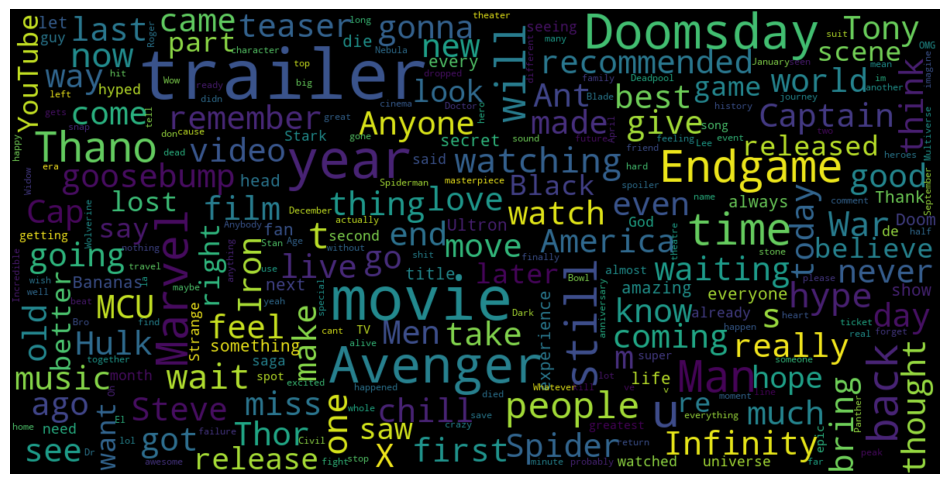

In [16]:
Avengers = Avengers_trailer['clean'].str.cat(sep=" ")

all_stopwords = STOPWORDS

wordcloud = WordCloud(
    background_color = 'black',
    stopwords = all_stopwords,
    max_words = 300,
    max_font_size = 30,
    scale = 3,
    random_state = 1,
    collocations = False
).generate(Avengers)

plt.figure(figsize=(12, 12))
plt.imshow(wordcloud, interpolation = 'bilinear')
plt.axis('off')
plt.show()


In [17]:
Avengers_trailer.columns

Index(['video_id', 'video_title', 'comment', 'clean'], dtype='object')

# Create a Manually Labeled Sample Subset 

#### The data set I got doesn't have a Sentiment label that is needed for the train and test split.

In [18]:
#sample for 500 reviews to label manually

sample_df = Avengers_trailer[['clean']].sample(n=500, random_state=42).copy()
sample_df['human_label'] = ""  #I will manually fill this in Excel with positive, negative or neutral
sample_df.to_csv('manual_validation_sample.csv', index=False)

In [19]:
sample_df.head(10)

,clean,human_label
423,Crazy getting this recommended in December 202...,
1102,I can’t believe this came out 7 years ago. Thi...,
811,It is a coincidence that this has been recomme...,
3154,The Movie that ended a Era for Marvel.,
5181,That moment when you realize this will be the ...,
4653,If spider man is died for real and won’t come ...,
1533,Had to revisit the greatest trailer in Superhe...,
2479,*sees movie's runtime* How's this movie going ...,
1671,July 2025??,
585,One of my top five best movies. Nothing else c...,


In [20]:
human_labelled = pd.read_csv('manually_validated_sample - with human labels.csv')
human_labelled['human_label'] = human_labelled['human_label'].str.strip().str.lower()
print(human_labelled['human_label'].value_counts(dropna=False))


human_label
positive    218
neutral     218
negative     64
Name: count, dtype: int64


In [21]:
human_labelled.head(10)

,clean,human_label
0,Crazy getting this recommended in December 202...,positive
1,I can’t believe this came out 7 years ago. Thi...,positive
2,It is a coincidence that this has been recomme...,neutral
3,The Movie that ended a Era for Marvel.,neutral
4,That moment when you realize this will be the ...,neutral
5,If spider man is died for real and won’t come ...,negative
6,Had to revisit the greatest trailer in Superhe...,positive
7,*sees movie's runtime* How's this movie going ...,neutral
8,July 2025??,neutral
9,One of my top five best movies. Nothing else c...,positive


In [22]:
# 1. Class Balance (counts and percentages)
print("=== Class Balance ===")
counts = human_labelled['human_label'].value_counts()
percentages = human_labelled['human_label'].value_counts(normalize=True) * 100
class_summary = pd.DataFrame({'Count': counts, 'Percentage (%)': percentages.round(2)})
print(class_summary)
print()

# 2. Average Text Length (in characters and words)
human_labelled['char_length'] = human_labelled['clean'].astype(str).str.len()
human_labelled['word_length'] = human_labelled['clean'].astype(str).str.split().str.len()

print("=== Average Text Length (Overall) ===")
print(f"Average Characters: {human_labelled['char_length'].mean():.2f}")
print(f"Average Words:      {human_labelled['word_length'].mean():.2f}")
print()

print("=== Average Text Length by Class ===")
print(human_labelled.groupby('human_label')[['char_length', 'word_length']].mean().round(2))
print()

# 3. Print 10 Random Examples per Class
print("=== 10 Random Examples per Class ===")
for sentiment in ['positive', 'neutral', 'negative']:
    print(f"\n--- {sentiment.upper()} ---")
    subset = human_labelled[human_labelled['human_label'] == sentiment]
    samples = subset['clean'].sample(n=min(10, len(subset)), random_state=42)
    for i, text in enumerate(samples, 1):
        print(f"{i}. {text}")

=== Class Balance ===
             Count  Percentage (%)
human_label                       
positive       218            43.6
neutral        218            43.6
negative        64            12.8

=== Average Text Length (Overall) ===
Average Characters: 65.69
Average Words:      12.36

=== Average Text Length by Class ===
             char_length  word_length
human_label                          
negative           57.02        11.19
neutral            62.86        11.68
positive           71.06        13.39

=== 10 Random Examples per Class ===

--- POSITIVE ---
1. Like this comments who got recommended after 7 years Waiting eagerly for Doomsday 🔥
2. When thanos spoke i got chills🔥
3. A masterpiece that came out 7 yeras ago
4. 1:49 the title card represents the “ash” of the dead coming back to re create those who died... awesome
5. Some people(Bastards) have disliked this video But not us! Not us!
6. Everytime I watch this trailer it reminds me exact moment of that time.
7. just wat

# Auto Label using Vader, then train and evaluate

### Generate sentiment labels - positive, neutral, negative

In [23]:
sia = SentimentIntensityAnalyzer()

# Neutralize Marvel-specific title words and common misspellings
for word in ["doom", "doomsday", "dooms", "doomsay", "doomed"]:
    sia.lexicon[word] = 0.0

def get_sentiment(text):
    score = sia.polarity_scores(str(text))["compound"]
    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

Avengers_trailer["sentiment"] = Avengers_trailer["clean"].apply(get_sentiment)
print(Avengers_trailer["sentiment"].value_counts())

sentiment
neutral     2070
positive    2044
negative    1179
Name: count, dtype: int64


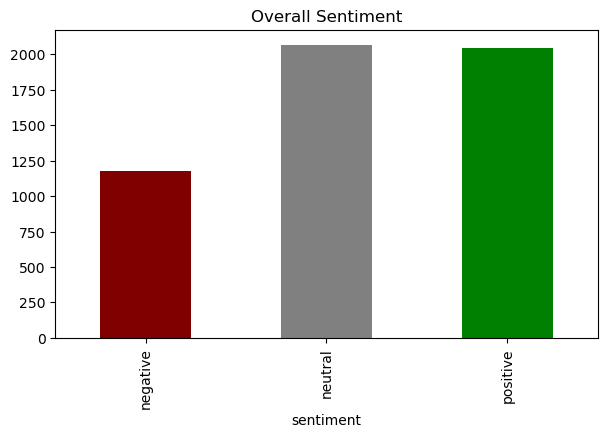

In [24]:
fig, ax = plt.subplots(figsize=(7,4))

Avengers_trailer['sentiment'].value_counts().reindex(['negative', 'neutral', 'positive']).plot.bar(
    ax=ax, color=['maroon', 'gray','green'])
ax.set_title("Overall Sentiment")

plt.show()

# Train & Test Split

In [25]:
# 1. Remove the 500 human-labeled validation rows from the main dataset before splitting
remaining_df = Avengers_trailer.drop(index=sample_df.index)

train, test = train_test_split(
    remaining_df,
    test_size=0.2,
    random_state=42,
    stratify=remaining_df["sentiment"]
)

y_train = train['sentiment'].to_numpy()
y_test = test['sentiment'].to_numpy()

print(f"Train data = {len(train)}; Test data = {len(test)}")

# 2. Update evaluate() to benchmark against your 500 human labels
y_human = human_labelled['human_label'].to_numpy()
preds = {}
results = {}
labels = ["negative", "neutral", "positive"]

Train data = 3834; Test data = 959


# Model 1 VADER - lexicon + rules, built for social media

### VADER Examples

In [26]:
 
vader = sia

examples = [
    "Is there any chance of iron man returning back in present 🤕",
    "saw this movie again today",
    "i’m discovering plot elements watching this trailer years later 😓",
    "I was too young to have known about avengers when this masterpiece came out. I've regretted not being able to watch not even one of the movies of this epic franchise in the theatres...when it came out...with the whole fandom🔥😭🥺 I can only hope doomsday would fill that gap for me😭♥️😔",
    "Endgame coming back to cinemas for doomsday I am excited for it",
    "We will return in Avengers Doomsday ❤️‍🩹",
    "You just had to be there man, new gen will never understand",
]

In [27]:
pd.DataFrame(
    [{"text": s, **vader.polarity_scores(s)} for s in examples]
).round(3)

,text,neg,neu,pos,compound
0,Is there any chance of iron man returning back...,0.000,0.867,0.133,0.250
1,saw this movie again today,0.000,1.000,0.000,0.000
2,i’m discovering plot elements watching this tr...,0.189,0.811,0.000,-0.422
3,I was too young to have known about avengers w...,0.139,0.696,0.165,0.472
4,Endgame coming back to cinemas for doomsday I ...,0.000,0.821,0.179,0.340
5,We will return in Avengers Doomsday ❤️‍🩹,0.000,1.000,0.000,0.000
6,"You just had to be there man, new gen will nev...",0.000,1.000,0.000,0.000


In [28]:
def vader_label(text, threshold=0.05):
    c = vader.polarity_scores(text)['compound']

    if c >= threshold:
        return "positive"
    elif c<= -threshold:
        return "negative"
    else: 
        return "neutral"

    

## Main Model

In [29]:
def evaluate(name, y_pred):
    y_pred = np.asarray(y_pred)
    preds[name] = y_pred

    results[name] = {
        "accuracy": accuracy_score(y_human, y_pred),
        "macro_f1": f1_score(y_human, y_pred, labels=labels, average="macro")
    }

    print(f"==={name} (Human Validation n={len(y_human)})===")
    print(classification_report(y_human, y_pred, labels=labels, digits=3, zero_division=0))

# 3. Evaluate Model 1 (VADER) on human_labelled
evaluate("VADER", human_labelled['clean'].apply(vader_label))

===VADER (Human Validation n=500)===
              precision    recall  f1-score   support

    negative      0.327     0.578     0.418        64
     neutral      0.631     0.541     0.583       218
    positive      0.620     0.569     0.593       218

    accuracy                          0.558       500
   macro avg      0.526     0.563     0.531       500
weighted avg      0.587     0.558     0.566       500



In [30]:
results

{'VADER': {'accuracy': 0.558, 'macro_f1': 0.5313655269448708}}

# Model 2: TextBlob - General Purpose Lexicon


#### sentiment - polarity;  subjectivity

In [31]:
examples = [
    "Is there any chance of iron man returning back in present 🤕",
    "saw this movie again today",
    "i’m discovering plot elements watching this trailer years later 😓",
    "I was too young to have known about avengers when this masterpiece came out. I've regretted not being able to watch not even one of the movies of this epic franchise in the theatres...when it came out...with the whole fandom🔥😭🥺 I can only hope doomsday would fill that gap for me😭♥️😔",
    "Endgame coming back to cinemas for doomsday I am excited for it",
    "We will return in Avengers Doomsday ❤️‍🩹",
    "You just had to be there man, new gen will never understand",
]

In [32]:
pd.DataFrame(
    [{
        "text": s,
        "polarity": TextBlob(s).sentiment.polarity,
        "subjectivity": TextBlob(s).sentiment.subjectivity}
        for s in examples]
)

,text,polarity,subjectivity
0,Is there any chance of iron man returning back...,0.000000,0.000000
1,saw this movie again today,0.000000,0.000000
2,i’m discovering plot elements watching this tr...,0.000000,0.000000
3,I was too young to have known about avengers w...,0.180000,0.565000
4,Endgame coming back to cinemas for doomsday I ...,0.187500,0.375000
5,We will return in Avengers Doomsday ❤️‍🩹,0.000000,0.000000
6,"You just had to be there man, new gen will nev...",0.136364,0.454545


### Main Model

In [33]:
def textblob_label(text, threshold=0.2):
    p = TextBlob(text).sentiment.polarity
    if p >= threshold:
        return "positive"
    elif p <= -threshold:
        return "negative"
    else:
        return "neutral"

In [34]:
evaluate("TextBlob", human_labelled['clean'].apply(textblob_label))

===TextBlob (Human Validation n=500)===
              precision    recall  f1-score   support

    negative      0.207     0.094     0.129        64
     neutral      0.508     0.830     0.631       218
    positive      0.626     0.330     0.432       218

    accuracy                          0.518       500
   macro avg      0.447     0.418     0.397       500
weighted avg      0.521     0.518     0.480       500



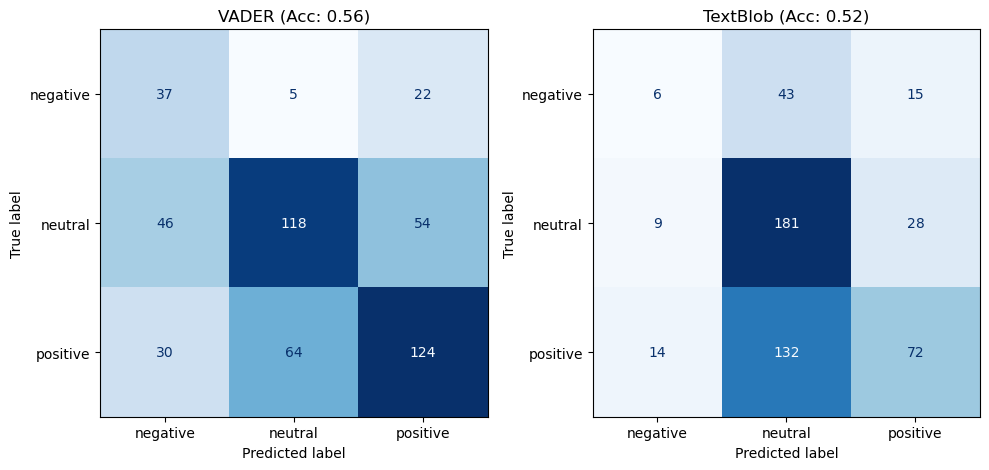

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))

for ax, name in zip(axes, ["VADER", "TextBlob"]):
    cm = confusion_matrix(y_human, preds[name], labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (Acc: {results[name]['accuracy']:.2f})")

plt.tight_layout()
plt.show()

In [36]:
side_by_side_preds = pd.DataFrame({
    "Comment": human_labelled["clean"],
    "Human Label": y_human,
    "VADER": preds["VADER"],
    "TextBlob": preds["TextBlob"]
})

# Show the first 15 rows 
side_by_side_preds.head(15)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(side_by_side_preds.head(15))

,Comment,Human Label,VADER,TextBlob
0,Crazy getting this recommended in December 2025! (Anybody here? 🔥🔥),positive,negative,negative
1,I can’t believe this came out 7 years ago. This was the first movie I saw 3 times in theaters,positive,neutral,positive
2,It is a coincidence that this has been recommended again.,neutral,positive,neutral
3,The Movie that ended a Era for Marvel.,neutral,positive,neutral
4,That moment when you realize this will be the only movie without a real Stan Lee reference,neutral,neutral,neutral
5,If spider man is died for real and won’t come back I’m will freaking sue,negative,negative,neutral
6,Had to revisit the greatest trailer in Superhero media ever.,positive,positive,positive
7,*sees movie's runtime* How's this movie going to be three hours long? *sees this trailer* How's this movie going to be three hours long? *movie kills Thanos in the first twenty minutes* HOW'S THIS MOVIE GOING TO BE THREE HOURS LONG?!?!?!,neutral,negative,neutral
8,July 2025??,neutral,neutral,neutral
9,One of my top five best movies. Nothing else compares,positive,positive,positive


# Model 3: NLTK + Naive Bayes

In [37]:
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.sentiment.util import mark_negation
from nltk import NaiveBayesClassifier, FreqDist
nltk.download("stopwords")



[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\home\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [38]:
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)

KEEP = {"no", "nor", "not", "very", "too", "against"}
STOP = {w for w in stopwords.words("english") if w not in KEEP and "n't" not in w}


In [39]:
def Avengers_tokens(text):
    tokens = tokenizer.tokenize(str(text))
    tokens = mark_negation(tokens)
    return [t for t in tokens 
        if t.replace("_NEG", "") not in STOP and re.search(r"\w", t)]


In [40]:
print(Avengers_tokens("I do NOT like this movie, the delay was too long"))

['not', 'like_NEG', 'movie_NEG', ',_NEG', 'delay_NEG', 'too_NEG', 'long_NEG']


## Main Model

In [41]:
train_tokens = [Avengers_tokens(t) for t in train['clean']]
test_tokens = [Avengers_tokens(t) for t in  test['clean']]

In [42]:
freq = FreqDist(w for tokens in train_tokens for w in tokens)
VOCAB = {w for w, _ in freq.most_common(3000)}

In [43]:
def nltk_features(tokens):
    return {w: True for w in set(tokens) if w in VOCAB} # bag-of-words

In [44]:
train_set =[(nltk_features(t), y) for t, y in zip(train_tokens, y_train)]

nb = NaiveBayesClassifier.train(train_set)
nb.show_most_informative_features(50)

Most Informative Features
                    best = True           positi : neutra =     86.8 : 1.0
                    good = True           positi : neutra =     46.6 : 1.0
             recommended = True           positi : neutra =     37.1 : 1.0
                  marvel = True           positi : neutra =     29.5 : 1.0
                    hope = True           positi : neutra =     26.2 : 1.0
                    like = True           positi : neutra =     25.5 : 1.0
                    dead = True           negati : positi =     23.6 : 1.0
                    wars = True           negati : neutra =     20.8 : 1.0
                     wow = True           positi : neutra =     20.1 : 1.0
                   civil = True           negati : neutra =     19.4 : 1.0
                     god = True           positi : neutra =     19.4 : 1.0
                     war = True           negati : neutra =     18.9 : 1.0
              marvel_NEG = True           positi : neutra =     16.0 : 1.0

In [45]:
# Tokenize the 500 human-labeled validation comments using your custom Avengers_tokens function
human_tokens = [Avengers_tokens(t) for t in human_labelled["clean"]]

evaluate("NLTK + Naive Bayes", [nb.classify(nltk_features(t)) for t in human_tokens])

===NLTK + Naive Bayes (Human Validation n=500)===
              precision    recall  f1-score   support

    negative      0.204     0.516     0.292        64
     neutral      0.652     0.206     0.314       218
    positive      0.565     0.697     0.624       218

    accuracy                          0.460       500
   macro avg      0.474     0.473     0.410       500
weighted avg      0.557     0.460     0.446       500



# Compare all methods

In [46]:
results

{'VADER': {'accuracy': 0.558, 'macro_f1': 0.5313655269448708},
 'TextBlob': {'accuracy': 0.518, 'macro_f1': 0.397375570467624},
 'NLTK + Naive Bayes': {'accuracy': 0.46, 'macro_f1': 0.40995140929014123}}

In [47]:
summary = pd.DataFrame(results).T.sort_values("macro_f1", ascending=False).round(3)
summary

,accuracy,macro_f1
VADER,0.558,0.531
NLTK + Naive Bayes,0.460,0.410
TextBlob,0.518,0.397


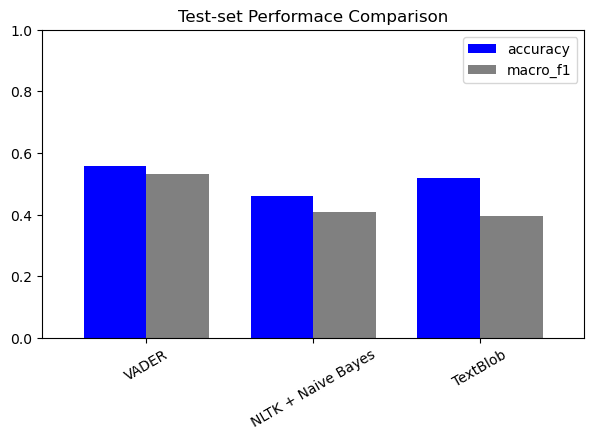

In [48]:
summary.plot.bar(figsize=(7,4), rot=30, width=0.75, color=['blue', 'gray'])
plt.title("Test-set Performace Comparison")
plt.ylim(0,1)
plt.show()

In [49]:
preds.items()

dict_items([('VADER', array(['negative', 'neutral', 'positive', 'positive', 'neutral',
       'negative', 'positive', 'negative', 'neutral', 'positive',
       'neutral', 'negative', 'positive', 'negative', 'positive',
       'positive', 'positive', 'negative', 'positive', 'positive',
       'negative', 'neutral', 'positive', 'positive', 'neutral',
       'negative', 'positive', 'positive', 'positive', 'positive',
       'neutral', 'neutral', 'negative', 'negative', 'neutral',
       'positive', 'negative', 'positive', 'positive', 'negative',
       'positive', 'negative', 'negative', 'positive', 'positive',
       'negative', 'positive', 'neutral', 'positive', 'positive',
       'neutral', 'positive', 'positive', 'neutral', 'negative',
       'positive', 'negative', 'neutral', 'neutral', 'positive',
       'neutral', 'positive', 'positive', 'neutral', 'positive',
       'positive', 'negative', 'negative', 'positive', 'positive',
       'positive', 'positive', 'positive', 'positive', '

# Confusion Matrix

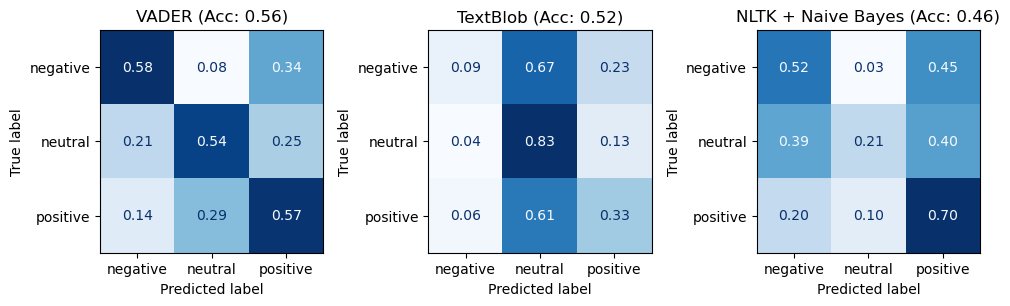

In [50]:
y_human_clean = pd.Series(y_human).astype(str).str.strip().str.lower() # Convert labels to text, changem them to lowercase and remove extra spaces.

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    y_pred_clean = pd.Series(y_pred).astype(str).str.strip().str.lower()
    
    cm = confusion_matrix(y_human_clean, y_pred_clean, labels=labels, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f"
    )
    ax.set_title(f"{name} (Acc: {results[name]['accuracy']:.2f})")

plt.tight_layout()
plt.show()

# Error Analysis

In [51]:
errors = human_labelled[['clean', 'human_label']].copy()
errors['VADER'] = preds['VADER']
errors['TextBlob'] = preds['TextBlob']
errors['NLTK + NB'] = preds['NLTK + Naive Bayes']

# Insert 'Avengers Movie trailer review' as the 1st column (position 0)
errors.insert(0, 'video_title', 'Avengers Movie trailer review')

# Save to CSV
errors.to_csv('error_analysis_results.csv', index=False, encoding='utf-8-sig')

pd.set_option('display.max_colwidth', 120)
errors.head(15)


,video_title,clean,human_label,VADER,TextBlob,NLTK + NB
0,Avengers Movie trailer review,Crazy getting this recommended in December 2025! (Anybody here? 🔥🔥),positive,negative,negative,positive
1,Avengers Movie trailer review,I can’t believe this came out 7 years ago. This was the first movie I saw 3 times in theaters,positive,neutral,positive,positive
2,Avengers Movie trailer review,It is a coincidence that this has been recommended again.,neutral,positive,neutral,positive
3,Avengers Movie trailer review,The Movie that ended a Era for Marvel.,neutral,positive,neutral,positive
4,Avengers Movie trailer review,That moment when you realize this will be the only movie without a real Stan Lee reference,neutral,neutral,neutral,negative
5,Avengers Movie trailer review,If spider man is died for real and won’t come back I’m will freaking sue,negative,negative,neutral,negative
6,Avengers Movie trailer review,Had to revisit the greatest trailer in Superhero media ever.,positive,positive,positive,positive
7,Avengers Movie trailer review,*sees movie's runtime* How's this movie going to be three hours long? *sees this trailer* How's this movie going to ...,neutral,negative,neutral,negative
8,Avengers Movie trailer review,July 2025??,neutral,neutral,neutral,neutral
9,Avengers Movie trailer review,One of my top five best movies. Nothing else compares,positive,positive,positive,positive


In [52]:
def evaluate_timed(name, predict_fn, texts, cost_per_1k=0.0):
    start_time = time.perf_counter()
    y_pred = np.asarray(predict_fn(texts))
    elapsed = time.perf_counter() - start_time
    sec_per_1k = (elapsed / len(texts)) * 1000

    preds[name] = y_pred
    results[name] = {
        "accuracy": accuracy_score(y_human, y_pred),
        "macro_f1": f1_score(y_human, y_pred, labels=labels, average="macro"),
        "sec_per_1k": round(sec_per_1k, 4),
        "cost_per_1k": cost_per_1k
    }

    print(f"=== {name} (n={len(y_human)} | {sec_per_1k:.4f} sec/1k | ${cost_per_1k:.4f}/1k) ===")
    print(classification_report(y_human, y_pred, labels=labels, digits=3, zero_division=0))

# Re-run Tier 1 & Tier 2 models with speed & cost tracking
evaluate_timed("VADER", lambda s: s.apply(vader_label), human_labelled["clean"], cost_per_1k=0.0)
evaluate_timed("TextBlob", lambda s: s.apply(textblob_label), human_labelled["clean"], cost_per_1k=0.0)
evaluate_timed(
    "NLTK + Naive Bayes",
    lambda s: [nb.classify(nltk_features(Avengers_tokens(t))) for t in s],
    human_labelled["clean"],
    cost_per_1k=0.0
)

# Display updated summary table with speed and cost
summary_df = pd.DataFrame(results).T.round(4)
display(summary_df)

=== VADER (n=500 | 0.3259 sec/1k | $0.0000/1k) ===
              precision    recall  f1-score   support

    negative      0.327     0.578     0.418        64
     neutral      0.631     0.541     0.583       218
    positive      0.620     0.569     0.593       218

    accuracy                          0.558       500
   macro avg      0.526     0.563     0.531       500
weighted avg      0.587     0.558     0.566       500

=== TextBlob (n=500 | 0.4598 sec/1k | $0.0000/1k) ===
              precision    recall  f1-score   support

    negative      0.207     0.094     0.129        64
     neutral      0.508     0.830     0.631       218
    positive      0.626     0.330     0.432       218

    accuracy                          0.518       500
   macro avg      0.447     0.418     0.397       500
weighted avg      0.521     0.518     0.480       500

=== NLTK + Naive Bayes (n=500 | 0.4062 sec/1k | $0.0000/1k) ===
              precision    recall  f1-score   support

    negative  

,accuracy,macro_f1,sec_per_1k,cost_per_1k
VADER,0.558,0.5314,0.3259,0.0
TextBlob,0.518,0.3974,0.4598,0.0
NLTK + Naive Bayes,0.460,0.4100,0.4062,0.0


# 0 Setup for Claude Sentiment

In [53]:
!pip install anthropic

# Hard Cases

Models detected: ['VADER', 'TextBlob', 'NLTK + NB']
Saved 30 hard cases to data/hard_cases_30.csv


,Model,Accuracy,Macro-F1,Hard-cases acc.
0,VADER,0.558,0.5314,0.0
2,NLTK + NB,0.460,0.4100,0.0
1,TextBlob,0.518,0.3974,0.0


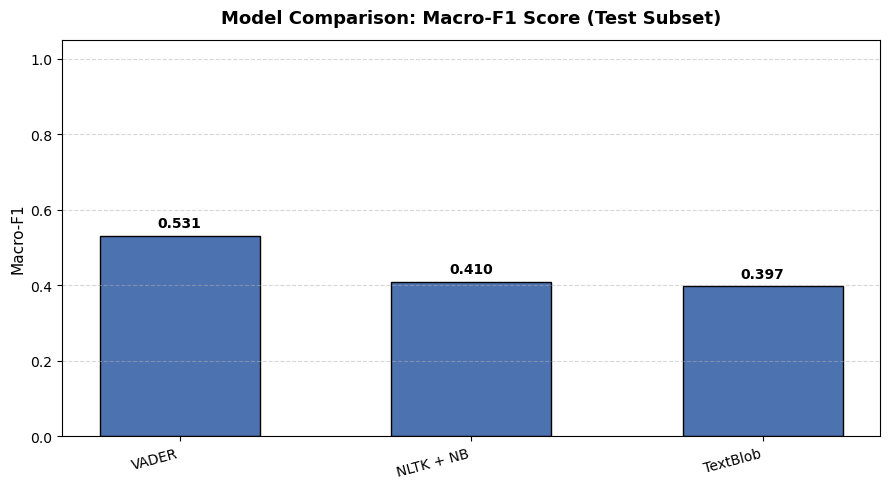

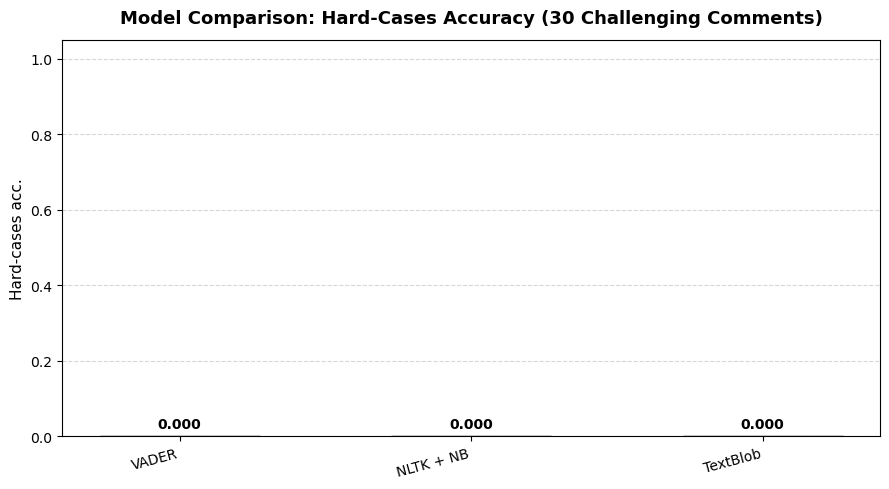

In [54]:
import os

# 1. Create Milestone 4 output folders
os.makedirs("data", exist_ok=True)
os.makedirs("results/charts", exist_ok=True)

# Load your evaluation CSV (or use `human_labelled` if already in memory)
df_eval = pd.read_csv("error_analysis_results.csv")

# Automatically detect model prediction columns (works before AND after adding Claude)
ignore_cols = {"video_title", "clean", "human_label"}
model_cols = [c for c in df_eval.columns if c not in ignore_cols]
print("Models detected:", model_cols)

# 2. Build a fixed 30-sentence Hard-Cases Set (10 per class)
# Difficulty score = how many classic/rule-based models got the row wrong
baseline_cols = [c for c in model_cols if "claude" not in c.lower()]
df_eval["num_errors"] = sum(df_eval[c] != df_eval["human_label"] for c in baseline_cols)

hard_cases_list = []
for label in ["positive", "neutral", "negative"]:
    subset = (
        df_eval[df_eval["human_label"] == label]
        .sort_values(by=["num_errors"], ascending=False)
        .head(10)
    )
    hard_cases_list.append(subset)

hard_cases_30 = pd.concat(hard_cases_list).drop(columns=["num_errors"]).reset_index(drop=True)
hard_cases_30.to_csv("data/hard_cases_30.csv", index=False)
print(f"Saved {len(hard_cases_30)} hard cases to data/hard_cases_30.csv")

# 3. Compute Milestone 4 Centerpiece Metrics Table
metrics_rows = []
for model in model_cols:
    acc = accuracy_score(df_eval["human_label"], df_eval[model])
    macro_f1 = f1_score(df_eval["human_label"], df_eval[model], average="macro")
    hard_acc = accuracy_score(hard_cases_30["human_label"], hard_cases_30[model])

    metrics_rows.append({
        "Model": model,
        "Accuracy": round(acc, 4),
        "Macro-F1": round(macro_f1, 4),
        "Hard-cases acc.": round(hard_acc, 4),
    })

metrics_df = pd.DataFrame(metrics_rows).sort_values(by="Macro-F1", ascending=False)
metrics_df.to_csv("results/metrics.csv", index=False)
display(metrics_df)

# 4. Generate Required Bar Charts
def plot_metric_bar(df, metric_col, title, filename, color):
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(df["Model"], df[metric_col], color=color, width=0.55, edgecolor="black")

    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_ylabel(metric_col, fontsize=11)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    plt.xticks(rotation=15, ha="right")

    # Add value labels on top of each bar
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )

    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

# Chart 1: Macro-F1 per model
plot_metric_bar(
    metrics_df,
    metric_col="Macro-F1",
    title="Model Comparison: Macro-F1 Score (Test Subset)",
    filename="results/charts/macro_f1_per_model.png",
    color="#4C72B0",
)

# Chart 2: Hard-cases accuracy per model
plot_metric_bar(
    metrics_df,
    metric_col="Hard-cases acc.",
    title="Model Comparison: Hard-Cases Accuracy (30 Challenging Comments)",
    filename="results/charts/hard_cases_accuracy_per_model.png",
    color="#DD8452",
)
